# Notebook 07: Evaluating Efficient First-Order Approximations for Geometric Training

## Research Objective
Training neural networks with **exact differential-geometric losses** requires nested symbolic automatic differentiation:
- **Volume-Element** ($\log\sqrt{\det g^{(L)}}$) and **Metric Anisotropy** ($\log(\tilde{g}^{(L)}_{11}/\tilde{g}^{(L)}_{22})$) require **2nd-order** mixed derivatives $\nabla_\theta \partial_x z$.
- **Gaussian Curvature** ($K^{(L)} = R_{1212}/\det\tilde{g}^{(L)}$) requires **3rd-order** mixed derivatives $\nabla_\theta \partial_x^2 z$.

In this notebook, we implement and benchmark **four principled approaches** that reduce compute and memory toward standard **1st-order `SGD` with Cross-Entropy loss** by replacing symbolic spatial derivatives with forward-only discrete or algebraic geometric operators:

1. **Approach 1 — Batched Finite-Difference Stencils (Pure 1st-Order Autodiff)**
2. **Approach 2 — Precomputed Point-Cloud $k$-NN Taylor Jet Operators (`1N` Single Forward Pass)**
3. **Approach 3 — Randomized Tangent-Plane Sketching / Hutchinson Directional Probes ($O(1)$ in Input Dimension $d_0$)**
4. **Approach 4 — Algebraic Order Reduction Before Autodiff (Gauss's Extrinsic-to-Intrinsic Identity)**

Dataset: moons (classes=2) | MLP: [2, 5, 10, 15, 10, 2] (hidden=tanh, out=identity)
Offline t=0 k-NN Jet Precomputation: 3.56 ms | Linear op: (220, 2, 10), Quadratic op: (220, 5, 16)
Approach 4 (Gauss Eq.) max |K_gauss - K_levi_civita| : 1.54e-13
Approach 1 (7-pt FD, h=2e-3) mean |K_fd - K_exact|   : 3.66e-05
Approach 2 (1N k-NN Jet) Pearson r(K_knn, K_exact)   : 0.5068


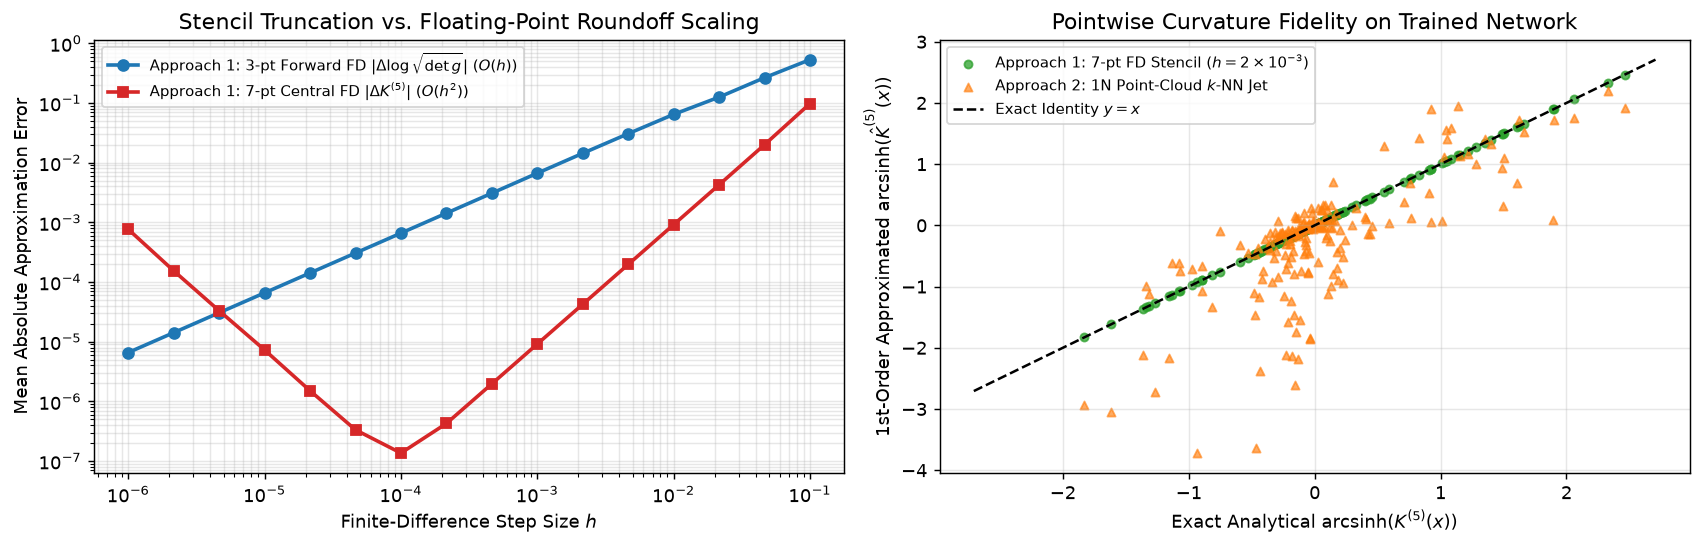

In [1]:
# =============================================================================
# USER CONFIGURATION
# =============================================================================
# 1. Toy Dataset Configuration (from sklearn.datasets synthetic generators)
#    Options: "moons", "circles", "blobs", "classification", "gaussian_quantiles"
DATASET_NAME = "moons"
N_CLASSES = 2                  # Number of classes (defaults to 2)
DATASET_PARAMS = {
    "n_train": 220,
    "n_test": 120,
    "noise": 0.10,
    "seed": 42,
}

# 2. Neural Network Layer Architecture: [input_dim, *hidden_dims, output_dim]
LAYER_DIMS = [2, 5, 10, 15, 10, 2]

# 3. Activation Functions for Hidden Layers and Output Layer
HIDDEN_ACTIVATION = "tanh"
OUTPUT_ACTIVATION = "identity"
# =============================================================================

import sys
from pathlib import Path
for p in [Path.cwd(), Path.cwd().parent]:
    if (p / "src" / "geometry.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import time
import numpy as np
import torch
import torch.nn as nn
from torch.profiler import ProfilerActivity, profile
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

from src.geometry import (
    MoonsMLP,
    get_synthetic_dataset,
    make_evaluation_grid,
    compute_layer_geometry,
    compute_layer_pullback_metric,
    compute_fast_graph_geometry,
    compute_fd_pullback_metric,
    compute_fd_graph_curvature,
    build_knn_jet_operator,
    compute_knn_jet_geometry,
    compute_sketched_pullback_metric,
    compute_sketched_plane_curvature,
    compute_coupled_geometric_metric,
    woodbury_coupled_ngd_direction,
    curvature_margin_loss,
    volume_contrastive_loss,
    anisotropy_margin_loss,
    scalar_geometric_predict,
)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10

CE_LAYER_DIMS = [*LAYER_DIMS[:-1], max(LAYER_DIMS[-1], N_CLASSES)]
CLASS_COLORS = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#ff7f0e", "#17becf"]

X_train, y_train, X_test, y_test = get_synthetic_dataset(
    dataset_name=DATASET_NAME,
    n_classes=N_CLASSES,
    input_dim=LAYER_DIMS[0],
    **DATASET_PARAMS,
)
xx, yy, grid_pts = make_evaluation_grid(X_train, n_grid=28, padding=0.45)

# Precompute offline t=0 point-cloud k-NN operators (Approach 2)
t0_knn = time.perf_counter()
knn_idx_lin, knn_op_lin = build_knn_jet_operator(X_train, k_neighbors=10, order=1, ridge=1e-4)
knn_idx_quad, knn_op_quad = build_knn_jet_operator(X_train, k_neighbors=16, order=2, ridge=1e-4)
knn_precomp_ms = (time.perf_counter() - t0_knn) * 1000.0
print(
    f"Dataset: {DATASET_NAME} (classes={N_CLASSES}) | MLP: {LAYER_DIMS} (hidden={HIDDEN_ACTIVATION}, out={OUTPUT_ACTIVATION})\n"
    f"Offline t=0 k-NN Jet Precomputation: {knn_precomp_ms:.2f} ms | Linear op: {tuple(knn_op_lin.shape)}, Quadratic op: {tuple(knn_op_quad.shape)}"
)

# Section 1: Numerical approximation fidelity vs. Exact Autodiff on a trained reference MLP
ref_mlp = MoonsMLP(
    layer_dims=CE_LAYER_DIMS,
    activation=HIDDEN_ACTIVATION,
    output_activation=OUTPUT_ACTIVATION,
    seed=7,
)
L_ref = ref_mlp.num_layers
ref_opt = torch.optim.SGD(ref_mlp.parameters(), lr=0.12, momentum=0.9)
ce_loss_fn = nn.CrossEntropyLoss()
for _ in range(100):
    ref_opt.zero_grad()
    ce_loss_fn(ref_mlp(X_train), y_train).backward()
    ref_opt.step()

with torch.no_grad():
    geom_exact_levi = compute_layer_geometry(ref_mlp, X_train, layer_idx=L_ref, metric_mode="graph")
    g_exact_gauss, K_exact_gauss = compute_fast_graph_geometry(ref_mlp, X_train)
    g_eucl_exact = compute_layer_pullback_metric(ref_mlp, X_train, layer_idx=L_ref, metric_mode="euclidean", eps=1e-6)
    lv_exact = 0.5 * torch.log(torch.clamp(torch.linalg.det(g_eucl_exact), min=1e-8))

    h_grid = np.logspace(-6, -1, 16)
    fd_vol_errs, fd_curv_errs = [], []
    for h_val in h_grid:
        g_fd_h = compute_fd_pullback_metric(ref_mlp, X_train, h=float(h_val), metric_mode="euclidean", eps=1e-6)
        lv_fd_h = 0.5 * torch.log(torch.clamp(torch.linalg.det(g_fd_h), min=1e-8))
        fd_vol_errs.append((lv_fd_h - lv_exact).abs().mean().item())

        _, K_fd_h = compute_fd_graph_curvature(ref_mlp, X_train, h=float(h_val))
        fd_curv_errs.append((K_fd_h - K_exact_gauss).abs().mean().item())

    _, K_fd_opt = compute_fd_graph_curvature(ref_mlp, X_train, h=2e-3)
    _, K_knn_est = compute_knn_jet_geometry(ref_mlp, X_train, knn_idx_quad, knn_op_quad, metric_mode="graph")

print(f"Approach 4 (Gauss Eq.) max |K_gauss - K_levi_civita| : {(K_exact_gauss - geom_exact_levi['K']).abs().max().item():.2e}")
print(f"Approach 1 (7-pt FD, h=2e-3) mean |K_fd - K_exact|   : {(K_fd_opt - K_exact_gauss).abs().mean().item():.2e}")
print(f"Approach 2 (1N k-NN Jet) Pearson r(K_knn, K_exact)   : {np.corrcoef(K_knn_est.numpy(), K_exact_gauss.numpy())[0, 1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.3))
axes[0].plot(h_grid, fd_vol_errs, "o-", lw=2.0, color="#1f77b4", label=r"Approach 1: 3-pt Forward FD $|\Delta \log\sqrt{\det g}|$ ($O(h)$)")
axes[0].plot(h_grid, fd_curv_errs, "s-", lw=2.0, color="#d62728", label=rf"Approach 1: 7-pt Central FD $|\Delta K^{{({L_ref})}}|$ ($O(h^2)$)")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel(r"Finite-Difference Step Size $h$")
axes[0].set_ylabel("Mean Absolute Approximation Error")
axes[0].set_title("Stencil Truncation vs. Floating-Point Roundoff Scaling")
axes[0].legend(fontsize=8.3)
axes[0].grid(alpha=0.3, which="both")

axes[1].scatter(np.arcsinh(K_exact_gauss.numpy()), np.arcsinh(K_fd_opt.numpy()), s=20, alpha=0.75, color="#2ca02c", label=r"Approach 1: 7-pt FD Stencil ($h=2\times 10^{-3}$)")
axes[1].scatter(np.arcsinh(K_exact_gauss.numpy()), np.arcsinh(K_knn_est.numpy()), s=20, alpha=0.65, color="#ff7f0e", marker="^", label="Approach 2: 1N Point-Cloud $k$-NN Jet")
lim_v = max(np.abs(np.arcsinh(K_exact_gauss.numpy())).max() * 1.1, 1.0)
axes[1].plot([-lim_v, lim_v], [-lim_v, lim_v], "k--", lw=1.4, label="Exact Identity $y = x$")
axes[1].set_xlabel(rf"Exact Analytical $\mathrm{{arcsinh}}(K^{{({L_ref})}}(x))$")
axes[1].set_ylabel(rf"1st-Order Approximated $\mathrm{{arcsinh}}(\hat{{K}}^{{({L_ref})}}(x))$")
axes[1].set_title("Pointwise Curvature Fidelity on Trained Network")
axes[1].legend(fontsize=8.3)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Step-Level Compute, Memory & Autograd Graph Benchmark (vs. `SGD` Cross-Entropy Baseline)

We benchmark a complete **forward + backward + `SGD.step()`** iteration across **14 configurations**, anchored by **`SGD + Cross-Entropy`** (`1st-Order` reference).

Method                             | Order |  Evals   | Latency (ms) |  Speedup | Memory (MB) |  Mem Save |  Nodes
------------------------------------------------------------------------------------------------------------------
SGD + Cross-Entropy                |  1st  |    1N    |         0.93 |     1.0x |        0.51 |      1.0x |     26
Vol: Exact 2nd-Order Autodiff      |  2nd  |  jacrev  |         3.70 |     1.0x |        3.49 |      1.0x |    107
Vol: App1 (3-pt FD Stencil)        |  1st  |    3N    |         1.92 |     1.9x |        1.87 |      1.9x |     56
Vol: App2 (1N k-NN Linear)         |  1st  |    1N    |         1.85 |     2.0x |        1.01 |      3.5x |     61
Vol: App3 (2-Probe Sketch)         |  1st  |    3N    |         2.25 |     1.6x |        2.06 |      1.7x |     72
Aniso: Exact 2nd-Order Autodiff    |  2nd  |  jacrev  |         5.32 |     1.0x |        3.59 |      1.0x |    114
Aniso: App1 (3-pt FD Stencil)      |  1st  |    3N    |         2.32 |     2.3x 

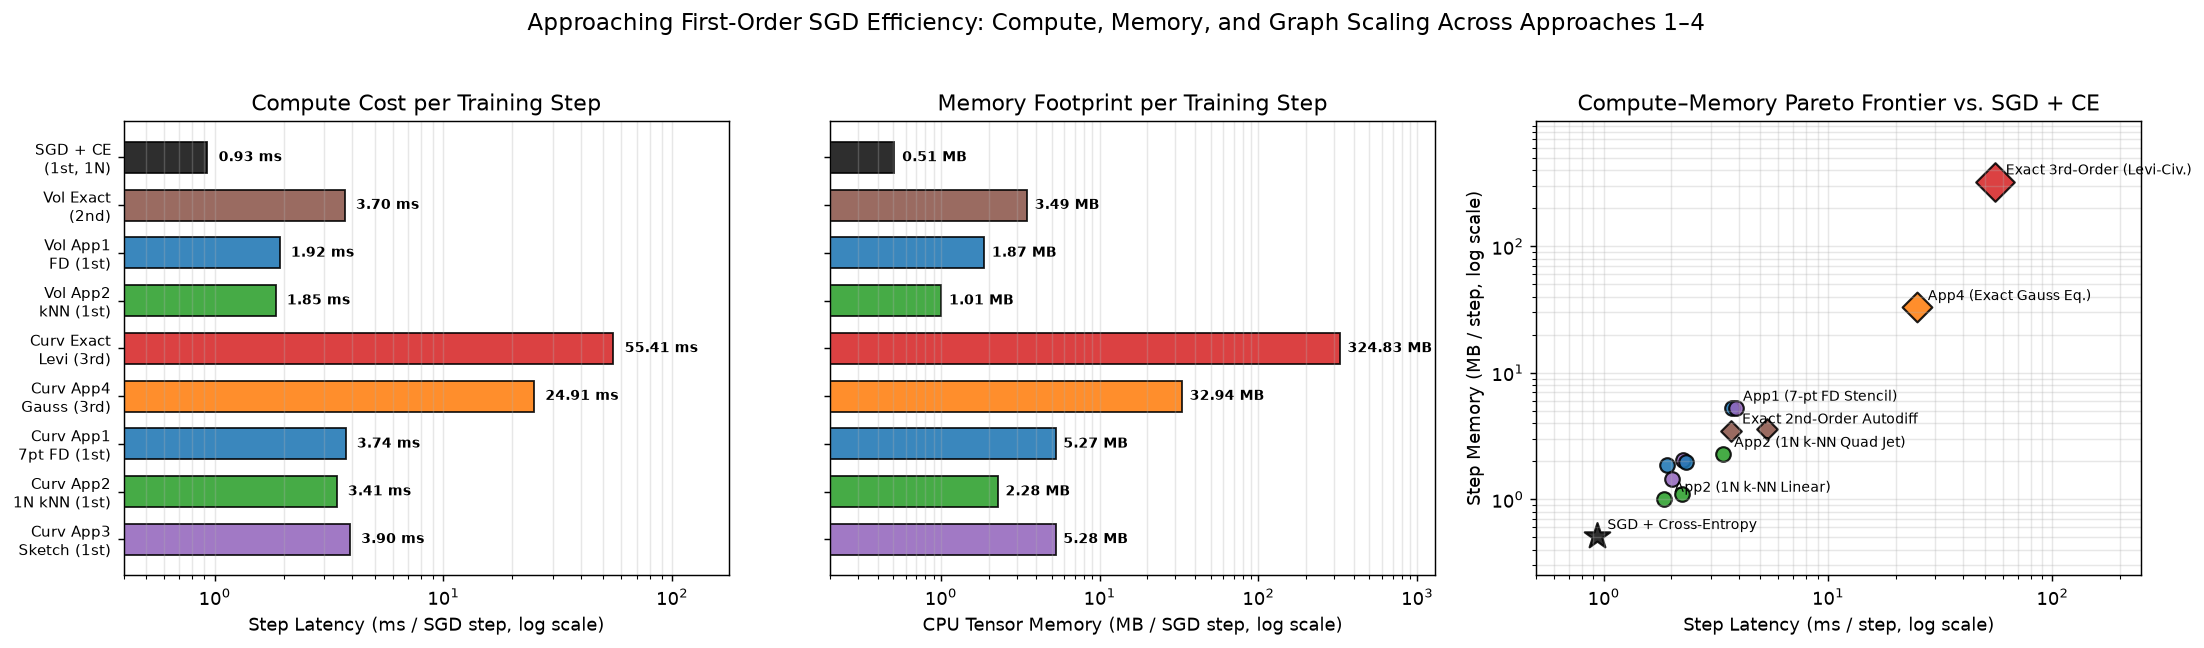

In [2]:
def count_autograd_nodes(grad_fn) -> int:
    visited = set()
    stack = [grad_fn]
    while stack:
        node = stack.pop()
        if node is None or node in visited:
            continue
        visited.add(node)
        for nxt, _ in getattr(node, "next_functions", []):
            stack.append(nxt)
    return len(visited)


def benchmark_sgd_step(loss_fn, model: MoonsMLP, n_repeats: int = 25):
    sgd = torch.optim.SGD(model.parameters(), lr=1e-4)

    sgd.zero_grad()
    l_warm = loss_fn()
    n_nodes = count_autograd_nodes(l_warm.grad_fn)
    l_warm.backward()
    sgd.step()

    with profile(activities=[ProfilerActivity.CPU], profile_memory=True) as prof:
        sgd.zero_grad()
        l_mem = loss_fn()
        l_mem.backward()
        sgd.step()
    mem_mb = sum(e.cpu_memory_usage for e in prof.key_averages() if e.cpu_memory_usage > 0) / (1024.0 * 1024.0)

    t0 = time.perf_counter()
    for _ in range(n_repeats):
        sgd.zero_grad()
        l_run = loss_fn()
        l_run.backward()
        sgd.step()
    step_ms = (time.perf_counter() - t0) * 1000.0 / n_repeats
    return step_ms, mem_mb, n_nodes


bench_net_ce = MoonsMLP(layer_dims=CE_LAYER_DIMS, activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
bench_net = MoonsMLP(layer_dims=LAYER_DIMS, activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
L = bench_net.num_layers
rng_probe = torch.Generator().manual_seed(42)

BENCHMARK_SUITE = [
    ("Baseline", "SGD + Cross-Entropy", "1st", "1N", bench_net_ce, lambda: ce_loss_fn(bench_net_ce(X_train), y_train), "#111111"),
    # Volume-Element Loss
    ("Volume", "Vol: Exact 2nd-Order Autodiff", "2nd", "jacrev", bench_net, lambda: volume_contrastive_loss(compute_layer_pullback_metric(bench_net, X_train, L, "euclidean", 1e-6, params=dict(bench_net.named_parameters())), y_train, 0.60, n_classes=N_CLASSES)[0], "#8c564b"),
    ("Volume", "Vol: App1 (3-pt FD Stencil)", "1st", "3N", bench_net, lambda: volume_contrastive_loss(compute_fd_pullback_metric(bench_net, X_train, metric_mode="euclidean"), y_train, 0.60, n_classes=N_CLASSES)[0], "#1f77b4"),
    ("Volume", "Vol: App2 (1N k-NN Linear)", "1st", "1N", bench_net, lambda: volume_contrastive_loss(compute_knn_jet_geometry(bench_net, X_train, knn_idx_lin, knn_op_lin, metric_mode="euclidean")[0], y_train, 0.60, n_classes=N_CLASSES)[0], "#2ca02c"),
    ("Volume", "Vol: App3 (2-Probe Sketch)", "1st", "3N", bench_net, lambda: volume_contrastive_loss(compute_sketched_pullback_metric(bench_net, X_train, n_probes=2, metric_mode="euclidean", generator=rng_probe)[0], y_train, 0.60, n_classes=N_CLASSES)[0], "#9467bd"),
    # Metric Anisotropy Loss
    ("Anisotropy", "Aniso: Exact 2nd-Order Autodiff", "2nd", "jacrev", bench_net, lambda: anisotropy_margin_loss(compute_layer_pullback_metric(bench_net, X_train, L, "graph", params=dict(bench_net.named_parameters())), y_train, 0.45, n_classes=N_CLASSES)[0], "#8c564b"),
    ("Anisotropy", "Aniso: App1 (3-pt FD Stencil)", "1st", "3N", bench_net, lambda: anisotropy_margin_loss(compute_fd_pullback_metric(bench_net, X_train, metric_mode="graph"), y_train, 0.45, n_classes=N_CLASSES)[0], "#1f77b4"),
    ("Anisotropy", "Aniso: App2 (1N k-NN Linear)", "1st", "1N", bench_net, lambda: anisotropy_margin_loss(compute_knn_jet_geometry(bench_net, X_train, knn_idx_lin, knn_op_lin, metric_mode="graph")[0], y_train, 0.45, n_classes=N_CLASSES)[0], "#2ca02c"),
    ("Anisotropy", "Aniso: App3 (1-Probe Hutch.)", "1st", "2N", bench_net, lambda: anisotropy_margin_loss(compute_sketched_pullback_metric(bench_net, X_train, n_probes=1, metric_mode="graph", generator=rng_probe)[0], y_train, 0.45, n_classes=N_CLASSES)[0], "#9467bd"),
    # Gaussian Curvature Loss
    ("Curvature", "Curv: Exact 3rd-Order (Levi-Civ.)", "3rd", "jacrev^3", bench_net, lambda: (lambda g: curvature_margin_loss(g["K"], y_train, g["g"], margin=0.40, n_classes=N_CLASSES)[0])(compute_layer_geometry(bench_net, X_train, L, "graph", params=dict(bench_net.named_parameters()))), "#d62728"),
    ("Curvature", "Curv: App4 (Exact Gauss Eq.)", "3rd", "jacfwd^2", bench_net, lambda: (lambda gK: curvature_margin_loss(gK[1], y_train, gK[0], margin=0.40, n_classes=N_CLASSES)[0])(compute_fast_graph_geometry(bench_net, X_train, params=dict(bench_net.named_parameters()))), "#ff7f0e"),
    ("Curvature", "Curv: App1 (7-pt FD Stencil)", "1st", "7N", bench_net, lambda: (lambda gK: curvature_margin_loss(gK[1], y_train, gK[0], margin=0.40, n_classes=N_CLASSES)[0])(compute_fd_graph_curvature(bench_net, X_train)), "#1f77b4"),
    ("Curvature", "Curv: App2 (1N k-NN Quad Jet)", "1st", "1N", bench_net, lambda: (lambda gK: curvature_margin_loss(gK[1], y_train, gK[0], margin=0.40, n_classes=N_CLASSES)[0])(compute_knn_jet_geometry(bench_net, X_train, knn_idx_quad, knn_op_quad, metric_mode="graph")), "#2ca02c"),
    ("Curvature", "Curv: App3 (Random 2-Plane)", "1st", "7N", bench_net, lambda: (lambda gK: curvature_margin_loss(gK[1], y_train, gK[0], margin=0.40, n_classes=N_CLASSES)[0])(compute_sketched_plane_curvature(bench_net, X_train, generator=rng_probe)), "#9467bd"),
]

bench_records = []
for grp, lbl, order_str, bmult, net_m, fn, col in BENCHMARK_SUITE:
    ms, mb, nodes = benchmark_sgd_step(fn, net_m)
    bench_records.append({
        "group": grp,
        "label": lbl,
        "order": order_str,
        "batch": bmult,
        "ms": ms,
        "mb": mb,
        "nodes": nodes,
        "color": col,
    })

exact_ref_by_group = {
    "Baseline": bench_records[0],
    "Volume": bench_records[1],
    "Anisotropy": bench_records[5],
    "Curvature": bench_records[9],
}

print(f"{'Method':<34} | {'Order':^5} | {'Evals':^8} | {'Latency (ms)':>12} | {'Speedup':>8} | {'Memory (MB)':>11} | {'Mem Save':>9} | {'Nodes':>6}")
print("-" * 114)
for rec in bench_records:
    ref = exact_ref_by_group[rec["group"]]
    sp = ref["ms"] / rec["ms"]
    msave = ref["mb"] / rec["mb"]
    print(
        f"{rec['label']:<34} | {rec['order']:^5} | {rec['batch']:^8} | {rec['ms']:12.2f} | {sp:7.1f}x | "
        f"{rec['mb']:11.2f} | {msave:8.1f}x | {rec['nodes']:6d}"
    )

plot_subset = [bench_records[i] for i in [0, 1, 2, 3, 9, 10, 11, 12, 13]]
short_labels = [
    "SGD + CE\n(1st, 1N)",
    "Vol Exact\n(2nd)",
    "Vol App1\nFD (1st)",
    "Vol App2\nkNN (1st)",
    "Curv Exact\nLevi (3rd)",
    "Curv App4\nGauss (3rd)",
    "Curv App1\n7pt FD (1st)",
    "Curv App2\n1N kNN (1st)",
    "Curv App3\nSketch (1st)",
]

fig, axes = plt.subplots(1, 3, figsize=(17.2, 4.8))
y_idx = np.arange(len(plot_subset))
cols_sub = [r["color"] for r in plot_subset]
ms_sub = [r["ms"] for r in plot_subset]
mb_sub = [r["mb"] for r in plot_subset]

bars0 = axes[0].barh(y_idx, ms_sub, color=cols_sub, edgecolor="k", alpha=0.88, height=0.65)
axes[0].set_xscale("log")
axes[0].set_yticks(y_idx)
axes[0].set_yticklabels(short_labels, fontsize=8.5)
axes[0].invert_yaxis()
axes[0].set_xlabel("Step Latency (ms / SGD step, log scale)")
axes[0].set_title("Compute Cost per Training Step")
axes[0].set_xlim(0.4, max(ms_sub) * 3.2)
axes[0].grid(axis="x", alpha=0.3, which="both")
for b, v in zip(bars0, ms_sub):
    axes[0].text(v * 1.12, b.get_y() + b.get_height() / 2, f"{v:.2f} ms", va="center", fontsize=8, fontweight="bold")

bars1 = axes[1].barh(y_idx, mb_sub, color=cols_sub, edgecolor="k", alpha=0.88, height=0.65)
axes[1].set_xscale("log")
axes[1].set_yticks(y_idx)
axes[1].set_yticklabels([""] * len(plot_subset))
axes[1].invert_yaxis()
axes[1].set_xlabel("CPU Tensor Memory (MB / SGD step, log scale)")
axes[1].set_title("Memory Footprint per Training Step")
axes[1].set_xlim(0.2, max(mb_sub) * 4.0)
axes[1].grid(axis="x", alpha=0.3, which="both")
for b, v in zip(bars1, mb_sub):
    axes[1].text(v * 1.12, b.get_y() + b.get_height() / 2, f"{v:.2f} MB", va="center", fontsize=8, fontweight="bold")

for rec in bench_records:
    marker = "*" if rec["group"] == "Baseline" else ("D" if rec["order"] != "1st" else "o")
    sz = 220 if rec["group"] == "Baseline" else max(rec["nodes"] * 0.22, 65)
    axes[2].scatter(rec["ms"], rec["mb"], s=sz, c=rec["color"], marker=marker, edgecolors="k", lw=1.2, alpha=0.88)

for i in [0, 1, 3, 9, 10, 11, 12]:
    r = bench_records[i]
    axes[2].annotate(r["label"].replace("Curv: ", "").replace("Vol: ", ""), (r["ms"], r["mb"]), textcoords="offset points", xytext=(6, 4), fontsize=7.8)

axes[2].set_xscale("log")
axes[2].set_yscale("log")
axes[2].set_xlabel("Step Latency (ms / step, log scale)")
axes[2].set_ylabel("Step Memory (MB / step, log scale)")
axes[2].set_title("Compute–Memory Pareto Frontier vs. SGD + CE")
axes[2].set_xlim(0.5, max(ms_sub) * 4.5)
axes[2].set_ylim(0.25, max(mb_sub) * 3.0)
axes[2].grid(alpha=0.3, which="both")

plt.suptitle("Approaching First-Order SGD Efficiency: Compute, Memory, and Graph Scaling Across Approaches 1–4", y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

## 3. End-to-End `SGD` Training Convergence & Exact Analytical Test Accuracy

Below we train **every method using `torch.optim.SGD` (`momentum = 0.9`)** from the same initialization (`seed = 7`) alongside the **`SGD + Cross-Entropy` baseline**, and evaluate held-out test accuracy at every checkpoint using the **exact analytical differential-geometric operators**.

Task & Training Method (All via SGD)         | Train Time (ms) | vs SGD+CE Time | Exact Analytical Test Acc
------------------------------------------------------------------------------------------------------------
Baseline: SGD + Cross-Entropy (1st-Order)    |           148.5 |          1.00x |                   100.00%
------------------------------------------------------------------------------------------------------------
Volume — Exact 2nd-Order Autodiff            |           543.5 |          3.66x |                   100.00%
Volume — App 1: 3-pt FD Stencil (1st)        |           306.2 |          2.06x |                   100.00%
Volume — App 2: 1N k-NN Linear (1st)         |           369.7 |          2.49x |                    97.50%
Volume — App 3: Random 2-Probe (1st)         |           322.3 |          2.17x |                   100.00%
------------------------------------------------------------------------------------------------------------
Anisotropy — Exact 2nd-Or

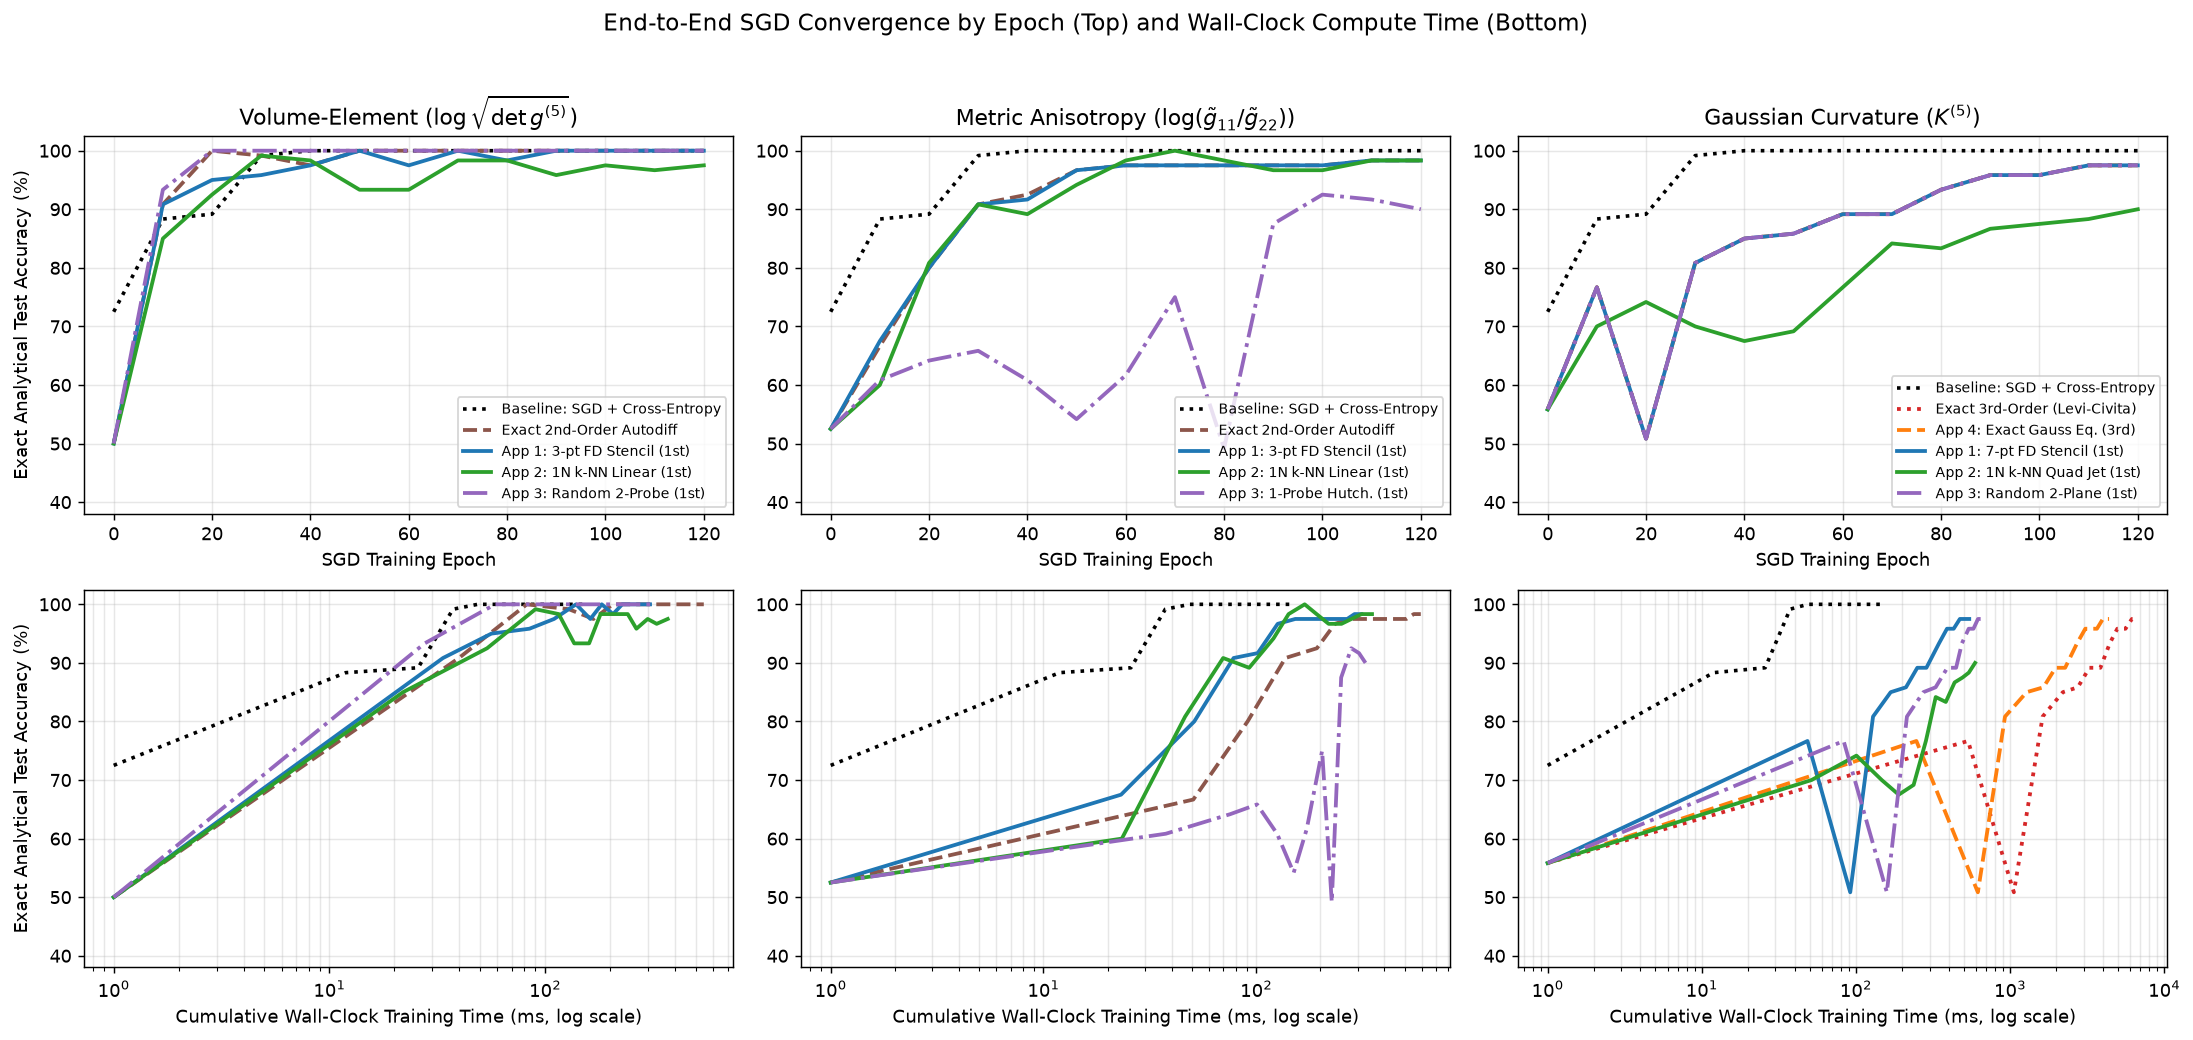

In [3]:
def exact_test_accuracy(mdl: MoonsMLP, task: str) -> float:
    l_out = mdl.num_layers
    with torch.no_grad():
        if task == "ce":
            return (mdl(X_test).argmax(dim=-1) == y_test).float().mean().item() * 100.0
        if task == "volume":
            g = compute_layer_pullback_metric(mdl, X_test, layer_idx=l_out, metric_mode="euclidean", eps=1e-6)
            lv = 0.5 * torch.log(torch.clamp(torch.linalg.det(g), min=1e-8))
            return (scalar_geometric_predict(lv, n_classes=N_CLASSES, margin=0.60) == y_test).float().mean().item() * 100.0
        if task == "anisotropy":
            g = compute_layer_pullback_metric(mdl, X_test, layer_idx=l_out, metric_mode="graph")
            lr = torch.log(torch.clamp(g[:, 0, 0], min=1e-8) / torch.clamp(g[:, 1, 1], min=1e-8))
            return (scalar_geometric_predict(lr, n_classes=N_CLASSES, margin=0.45) == y_test).float().mean().item() * 100.0
        if task == "curvature":
            _, K = compute_fast_graph_geometry(mdl, X_test)
            return (scalar_geometric_predict(K, n_classes=N_CLASSES, margin=0.40) == y_test).float().mean().item() * 100.0
    raise ValueError(task)


def run_sgd_training(task: str, approx_mode: str, epochs: int = 120, lr: float = 0.06, seed: int = 7):
    dims_use = CE_LAYER_DIMS if task == "ce" else LAYER_DIMS
    mdl = MoonsMLP(
        layer_dims=dims_use,
        activation=HIDDEN_ACTIVATION,
        output_activation=OUTPUT_ACTIVATION,
        seed=seed,
    )
    l_out = mdl.num_layers
    opt = torch.optim.SGD(mdl.parameters(), lr=lr, momentum=0.9)
    rng = torch.Generator().manual_seed(seed + 100)

    eval_epochs, acc_curve, time_ms_curve, loss_curve = [0], [exact_test_accuracy(mdl, task)], [0.0], []
    elapsed_train_ms = 0.0

    for ep in range(1, epochs + 1):
        t0 = time.perf_counter()
        opt.zero_grad()

        if task == "ce":
            loss = ce_loss_fn(mdl(X_train), y_train)
        elif task == "volume":
            if approx_mode == "exact":
                g = compute_layer_pullback_metric(mdl, X_train, l_out, "euclidean", 1e-6, params=dict(mdl.named_parameters()))
            elif approx_mode == "app1_fd":
                g = compute_fd_pullback_metric(mdl, X_train, metric_mode="euclidean")
            elif approx_mode == "app2_knn":
                g, _ = compute_knn_jet_geometry(mdl, X_train, knn_idx_lin, knn_op_lin, metric_mode="euclidean")
            elif approx_mode == "app3_sketch":
                g, _ = compute_sketched_pullback_metric(mdl, X_train, n_probes=2, metric_mode="euclidean", generator=rng)
            loss, _ = volume_contrastive_loss(g, y_train, margin=0.60, n_classes=N_CLASSES)
        elif task == "anisotropy":
            if approx_mode == "exact":
                g = compute_layer_pullback_metric(mdl, X_train, l_out, "graph", params=dict(mdl.named_parameters()))
            elif approx_mode == "app1_fd":
                g = compute_fd_pullback_metric(mdl, X_train, metric_mode="graph")
            elif approx_mode == "app2_knn":
                g, _ = compute_knn_jet_geometry(mdl, X_train, knn_idx_lin, knn_op_lin, metric_mode="graph")
            elif approx_mode == "app3_sketch":
                g, _ = compute_sketched_pullback_metric(mdl, X_train, n_probes=1, metric_mode="graph", generator=rng)
            loss, _ = anisotropy_margin_loss(g, y_train, margin=0.45, n_classes=N_CLASSES)
        elif task == "curvature":
            if approx_mode == "exact_levi":
                gm = compute_layer_geometry(mdl, X_train, l_out, "graph", params=dict(mdl.named_parameters()))
                g, K = gm["g"], gm["K"]
            elif approx_mode == "app4_gauss":
                g, K = compute_fast_graph_geometry(mdl, X_train, params=dict(mdl.named_parameters()))
            elif approx_mode == "app1_fd":
                g, K = compute_fd_graph_curvature(mdl, X_train)
            elif approx_mode == "app2_knn":
                g, K = compute_knn_jet_geometry(mdl, X_train, knn_idx_quad, knn_op_quad, metric_mode="graph")
            elif approx_mode == "app3_sketch":
                g, K = compute_sketched_plane_curvature(mdl, X_train, generator=rng)
            loss, _ = curvature_margin_loss(K, y_train, g, margin=0.40, lambda_vol=0.02, lambda_iso=0.005, k_clip=10.0, n_classes=N_CLASSES)
        else:
            raise ValueError(task)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(mdl.parameters(), max_norm=5.0)
        opt.step()
        elapsed_train_ms += (time.perf_counter() - t0) * 1000.0
        loss_curve.append(loss.item())

        if ep % 10 == 0 or ep == epochs:
            eval_epochs.append(ep)
            acc_curve.append(exact_test_accuracy(mdl, task))
            time_ms_curve.append(elapsed_train_ms)

    return mdl, {
        "epochs": eval_epochs,
        "acc": acc_curve,
        "time_ms": time_ms_curve,
        "final_loss": loss_curve[-1],
        "total_ms": elapsed_train_ms,
    }


N_EPOCHS = 120
ce_mdl, ce_hist = run_sgd_training("ce", "exact", epochs=N_EPOCHS, lr=0.12)

TRAINING_MATRIX = {
    "volume": [
        ("exact", "Exact 2nd-Order Autodiff", 0.06, "#8c564b", "--"),
        ("app1_fd", "App 1: 3-pt FD Stencil (1st)", 0.06, "#1f77b4", "-"),
        ("app2_knn", "App 2: 1N k-NN Linear (1st)", 0.025, "#2ca02c", "-"),
        ("app3_sketch", "App 3: Random 2-Probe (1st)", 0.06, "#9467bd", "-."),
    ],
    "anisotropy": [
        ("exact", "Exact 2nd-Order Autodiff", 0.08, "#8c564b", "--"),
        ("app1_fd", "App 1: 3-pt FD Stencil (1st)", 0.08, "#1f77b4", "-"),
        ("app2_knn", "App 2: 1N k-NN Linear (1st)", 0.08, "#2ca02c", "-"),
        ("app3_sketch", "App 3: 1-Probe Hutch. (1st)", 0.08, "#9467bd", "-."),
    ],
    "curvature": [
        ("exact_levi", "Exact 3rd-Order (Levi-Civita)", 0.045, "#d62728", ":"),
        ("app4_gauss", "App 4: Exact Gauss Eq. (3rd)", 0.045, "#ff7f0e", "--"),
        ("app1_fd", "App 1: 7-pt FD Stencil (1st)", 0.045, "#1f77b4", "-"),
        ("app2_knn", "App 2: 1N k-NN Quad Jet (1st)", 0.035, "#2ca02c", "-"),
        ("app3_sketch", "App 3: Random 2-Plane (1st)", 0.045, "#9467bd", "-."),
    ],
}

trained_models = {t: {} for t in TRAINING_MATRIX}
print(f"{'Task & Training Method (All via SGD)':<44} | {'Train Time (ms)':>15} | {'vs SGD+CE Time':>14} | {'Exact Analytical Test Acc':>25}")
print("-" * 108)
print(f"{'Baseline: SGD + Cross-Entropy (1st-Order)':<44} | {ce_hist['total_ms']:15.1f} | {'1.00x':>14} | {ce_hist['acc'][-1]:24.2f}%")
print("-" * 108)

for t_name, specs in TRAINING_MATRIX.items():
    for mode_key, label, lr_val, col, ls in specs:
        m_tr, h_tr = run_sgd_training(t_name, mode_key, epochs=N_EPOCHS, lr=lr_val)
        trained_models[t_name][mode_key] = (m_tr, h_tr, label, col, ls)
        rel_time = h_tr["total_ms"] / ce_hist["total_ms"]
        print(f"{f'{t_name.capitalize()} — {label}':<44} | {h_tr['total_ms']:15.1f} | {f'{rel_time:.2f}x':>14} | {h_tr['acc'][-1]:24.2f}%")
    print("-" * 108)

fig, axes = plt.subplots(2, 3, figsize=(17.0, 7.8))
task_titles = {
    "volume": rf"Volume-Element ($\log\sqrt{{\det g^{{({L})}}}}$)",
    "anisotropy": r"Metric Anisotropy ($\log(\tilde{g}_{11}/\tilde{g}_{22})$)",
    "curvature": rf"Gaussian Curvature ($K^{{({L})}}$)",
}

for col_idx, t_name in enumerate(["volume", "anisotropy", "curvature"]):
    axes[0, col_idx].plot(ce_hist["epochs"], ce_hist["acc"], "k:", lw=2.0, label="Baseline: SGD + Cross-Entropy")
    axes[1, col_idx].plot(np.maximum(ce_hist["time_ms"], 1.0), ce_hist["acc"], "k:", lw=2.0, label="Baseline: SGD + Cross-Entropy")

    for mode_key, (_, h_tr, label, col, ls) in trained_models[t_name].items():
        axes[0, col_idx].plot(h_tr["epochs"], h_tr["acc"], color=col, ls=ls, lw=2.1, label=label)
        axes[1, col_idx].plot(np.maximum(h_tr["time_ms"], 1.0), h_tr["acc"], color=col, ls=ls, lw=2.1, label=label)

    axes[0, col_idx].set_title(task_titles[t_name])
    axes[0, col_idx].set_xlabel("SGD Training Epoch")
    axes[0, col_idx].set_ylim(min(38.0, 100.0 / N_CLASSES - 10.0), 102.5)
    axes[0, col_idx].grid(alpha=0.3)
    axes[0, col_idx].legend(fontsize=7.6, loc="lower right")

    axes[1, col_idx].set_xscale("log")
    axes[1, col_idx].set_xlabel("Cumulative Wall-Clock Training Time (ms, log scale)")
    axes[1, col_idx].set_ylim(min(38.0, 100.0 / N_CLASSES - 10.0), 102.5)
    axes[1, col_idx].grid(alpha=0.3, which="both")

axes[0, 0].set_ylabel("Exact Analytical Test Accuracy (%)")
axes[1, 0].set_ylabel("Exact Analytical Test Accuracy (%)")
plt.suptitle("End-to-End SGD Convergence by Epoch (Top) and Wall-Clock Compute Time (Bottom)", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

## 4. Exact Analytical Decision Landscapes Learned via 1st-Order Approximations

We evaluate the **exact analytical** log-volume field $\log\sqrt{\det g^{(L)}(x)}$ (Row 0) and **exact analytical** Gaussian curvature $\mathrm{arcsinh}(K^{(L)}(x))$ (Row 1) across the ambient 2D plane.

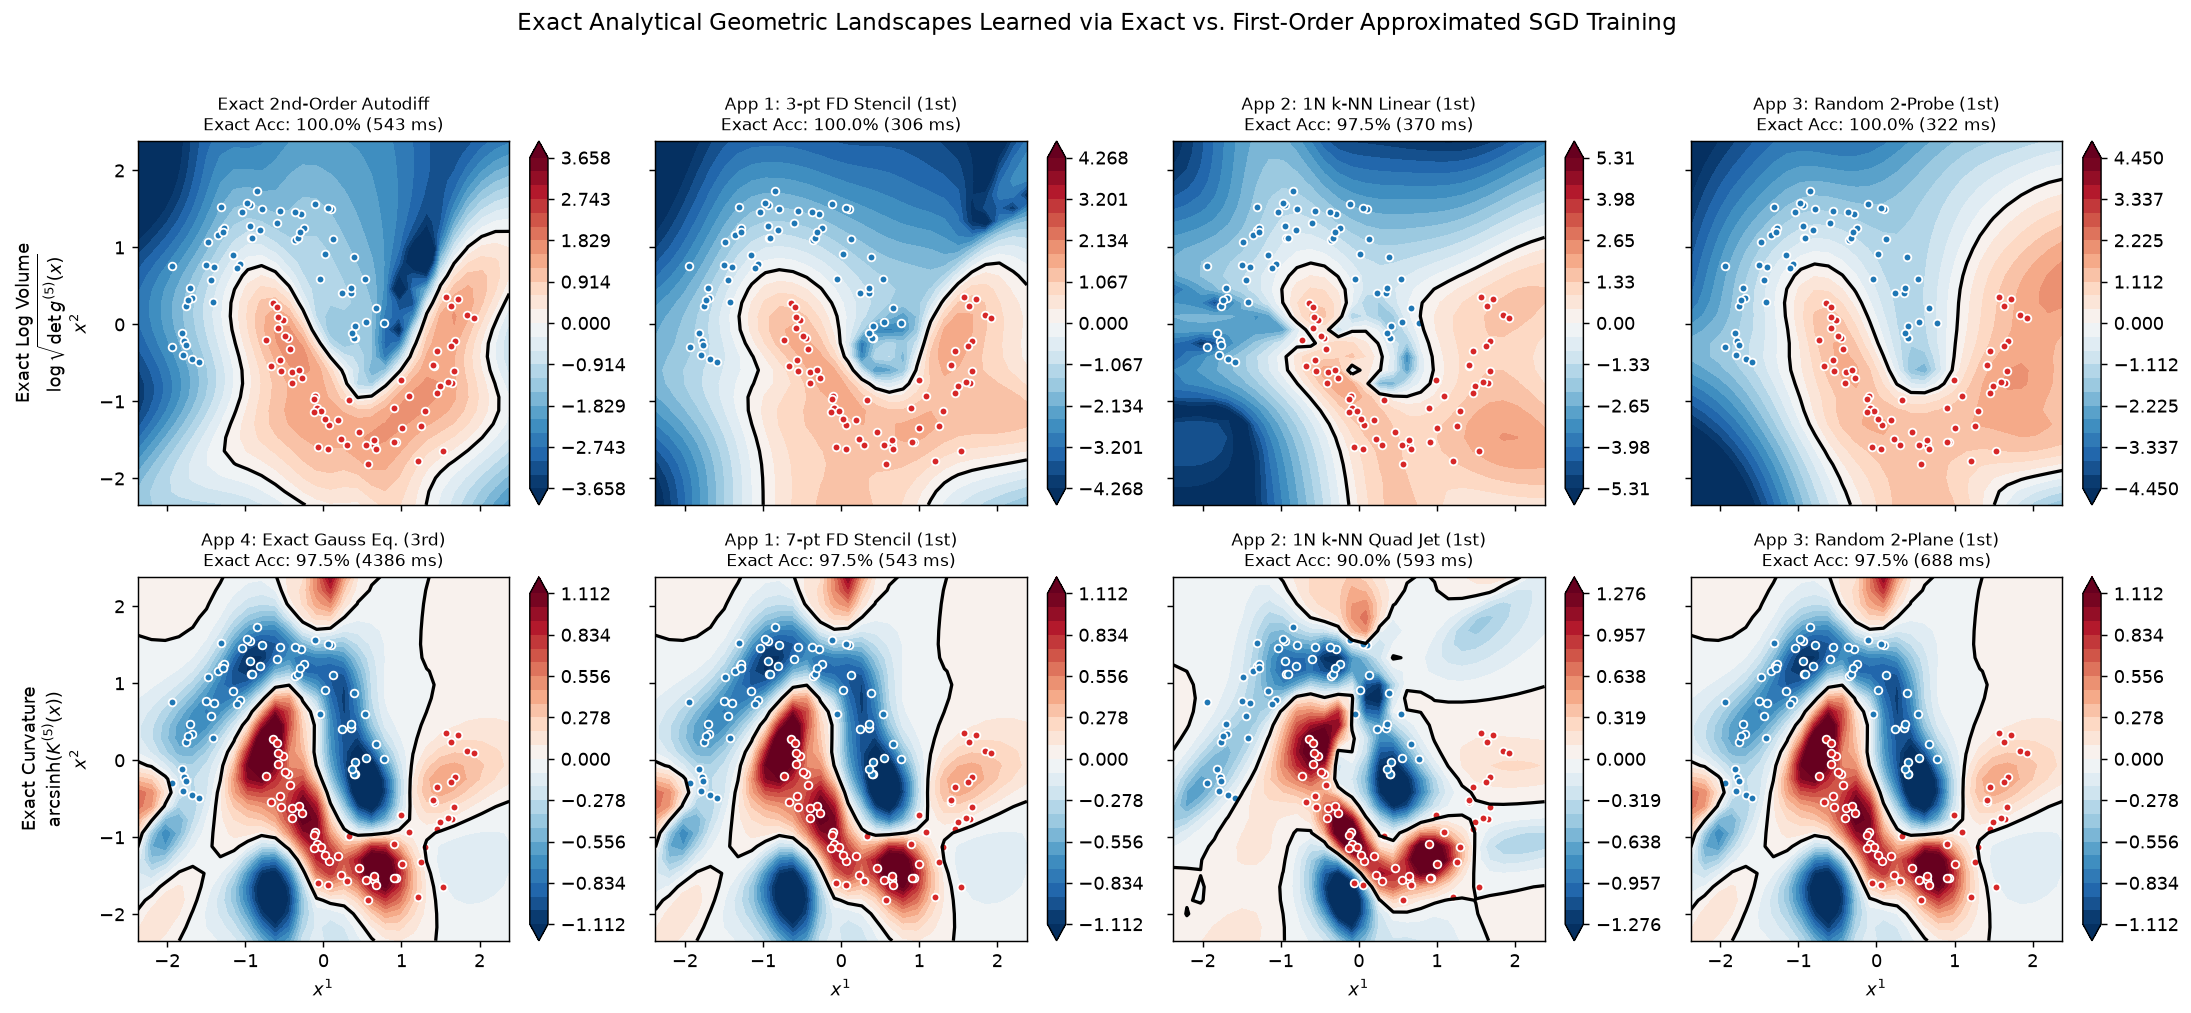

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(17.0, 7.6), sharex=True, sharey=True)

vol_cols = [
    ("exact", "Exact 2nd-Order Autodiff"),
    ("app1_fd", "App 1: 3-pt FD Stencil (1st)"),
    ("app2_knn", "App 2: 1N k-NN Linear (1st)"),
    ("app3_sketch", "App 3: Random 2-Probe (1st)"),
]
curv_cols = [
    ("app4_gauss", "App 4: Exact Gauss Eq. (3rd)"),
    ("app1_fd", "App 1: 7-pt FD Stencil (1st)"),
    ("app2_knn", "App 2: 1N k-NN Quad Jet (1st)"),
    ("app3_sketch", "App 3: Random 2-Plane (1st)"),
]

for c_idx, (m_key, c_title) in enumerate(vol_cols):
    mdl, h_tr, _, _, _ = trained_models["volume"][m_key]
    with torch.no_grad():
        g_grid = compute_layer_pullback_metric(mdl, grid_pts, layer_idx=mdl.num_layers, metric_mode="euclidean", eps=1e-6)
        fld = (0.5 * torch.log(torch.clamp(torch.linalg.det(g_grid), min=1e-8))).numpy().reshape(xx.shape)
    vm = float(max(np.percentile(np.abs(fld), 96), 0.25))
    im = axes[0, c_idx].contourf(xx, yy, fld, levels=np.linspace(-vm, vm, 25), cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-vm, vcenter=0.0, vmax=vm), extend="both")
    if fld.min() < 0.0 < fld.max():
        axes[0, c_idx].contour(xx, yy, fld, levels=[0.0], colors="k", linewidths=1.8)
    for c in range(N_CLASSES):
        mc = y_test == c
        axes[0, c_idx].scatter(X_test[mc, 0], X_test[mc, 1], c=CLASS_COLORS[c % len(CLASS_COLORS)], edgecolors="w", s=18)
    axes[0, c_idx].set_title(f"{c_title}\nExact Acc: {h_tr['acc'][-1]:.1f}% ({h_tr['total_ms']:.0f} ms)", fontsize=9.5)
    plt.colorbar(im, ax=axes[0, c_idx], fraction=0.046)

for c_idx, (m_key, c_title) in enumerate(curv_cols):
    mdl, h_tr, _, _, _ = trained_models["curvature"][m_key]
    with torch.no_grad():
        _, K_grid = compute_fast_graph_geometry(mdl, grid_pts)
        fld = np.arcsinh(K_grid.numpy()).reshape(xx.shape)
    vm = float(max(np.percentile(np.abs(fld), 96), 0.25))
    im = axes[1, c_idx].contourf(xx, yy, fld, levels=np.linspace(-vm, vm, 25), cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-vm, vcenter=0.0, vmax=vm), extend="both")
    if fld.min() < 0.0 < fld.max():
        axes[1, c_idx].contour(xx, yy, fld, levels=[0.0], colors="k", linewidths=1.8)
    for c in range(N_CLASSES):
        mc = y_test == c
        axes[1, c_idx].scatter(X_test[mc, 0], X_test[mc, 1], c=CLASS_COLORS[c % len(CLASS_COLORS)], edgecolors="w", s=18)
    axes[1, c_idx].set_title(f"{c_title}\nExact Acc: {h_tr['acc'][-1]:.1f}% ({h_tr['total_ms']:.0f} ms)", fontsize=9.5)
    axes[1, c_idx].set_xlabel("$x^1$")
    plt.colorbar(im, ax=axes[1, c_idx], fraction=0.046)

axes[0, 0].set_ylabel("Exact Log Volume\n" + rf"$\log\sqrt{{\det g^{{({L})}}(x)}}$" + "\n$x^2$")
axes[1, 0].set_ylabel("Exact Curvature\n" + rf"$\mathrm{{arcsinh}}(K^{{({L})}}(x))$" + "\n$x^2$")
plt.suptitle("Exact Analytical Geometric Landscapes Learned via Exact vs. First-Order Approximated SGD Training", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

## 5. High-Dimensional Input Scaling ($d_0 = 2 \to 128$): Why Randomized Tangent Sketching Wins

  d_0 |   SGD+CE (ms/MB) |   Exact 2nd (ms/MB) |    Coord FD (ms/MB) |  App3 1-Probe (ms/MB) |  App3 2-Plane K (ms/MB)
--------------------------------------------------------------------------------------------------------------------
    2 |   9.76 /  0.24 |    11.89 /   1.57 |     1.98 /   0.86 |      1.48 /   0.56 |       3.40 /   2.69
    4 |   7.96 /  0.24 |     9.49 /   1.74 |     2.00 /   1.51 |      1.70 /   0.62 |       3.45 /   2.71
    8 |   7.52 /  0.25 |    12.86 /   2.32 |     2.04 /   3.07 |      1.22 /   0.83 |       3.41 /   2.77
   16 |   8.19 /  0.25 |    11.55 /   4.41 |     2.15 /   7.12 |      1.26 /   1.61 |       3.40 /   2.87
   32 |   8.17 /  0.26 |    12.09 /  12.35 |     3.97 /  19.00 |      2.06 /   4.71 |       4.47 /   3.08
   64 |   8.37 /  0.27 |    15.52 /  43.27 |     6.35 /  57.85 |      1.83 /  16.93 |       3.62 /   3.49
  128 |   8.29 /  0.29 |    12.68 / 165.31 |    11.00 / 195.93 |      2.52 /  65.58 |       3.57 /   4.34


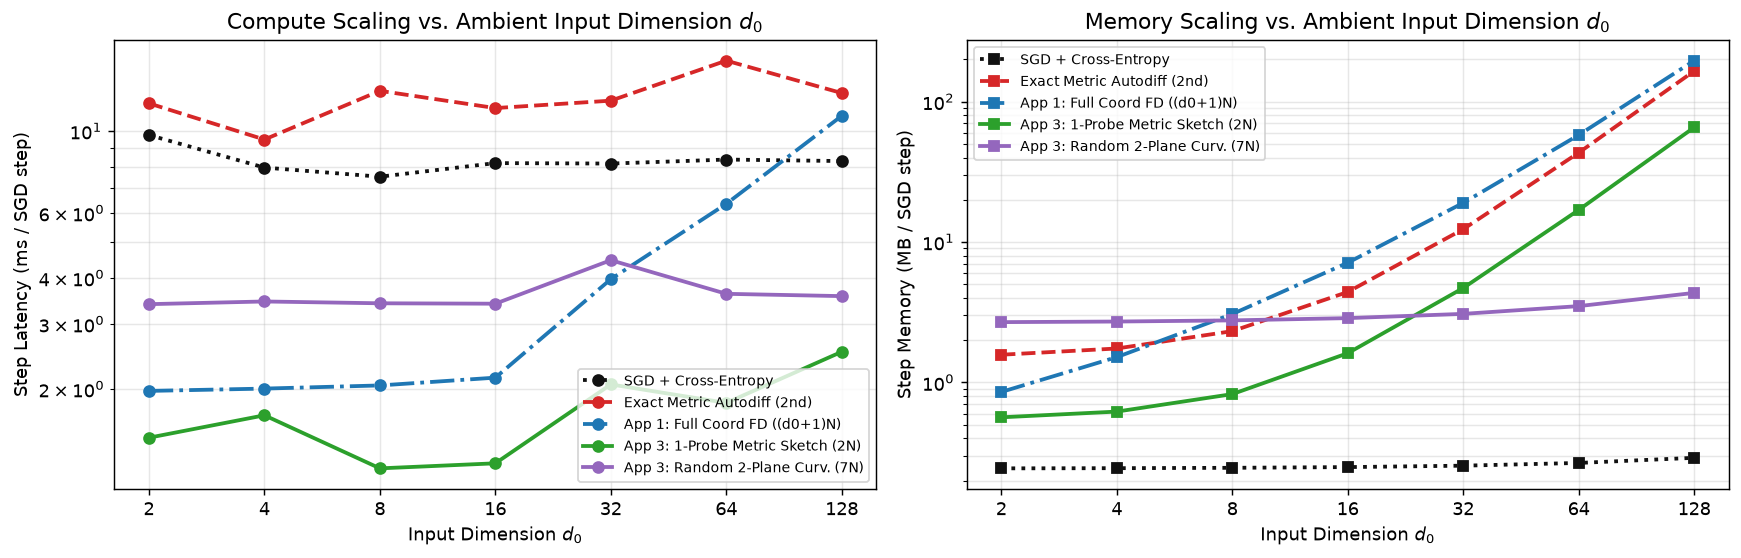

In [5]:
dims_to_test = [2, 4, 8, 16, 32, 64, 128]
N_hd = 128
scaling_res = {
    "SGD + Cross-Entropy": {"ms": [], "mb": [], "col": "#111111", "ls": ":"},
    "Exact Metric Autodiff (2nd)": {"ms": [], "mb": [], "col": "#d62728", "ls": "--"},
    "App 1: Full Coord FD ((d0+1)N)": {"ms": [], "mb": [], "col": "#1f77b4", "ls": "-."},
    "App 3: 1-Probe Metric Sketch (2N)": {"ms": [], "mb": [], "col": "#2ca02c", "ls": "-"},
    "App 3: Random 2-Plane Curv. (7N)": {"ms": [], "mb": [], "col": "#9467bd", "ls": "-"},
}

rng_hd = torch.Generator().manual_seed(77)
for d0 in dims_to_test:
    X_hd = torch.randn(N_hd, d0, dtype=torch.float64)
    y_hd = torch.randint(0, N_CLASSES, (N_hd,))
    mlp_hd = MoonsMLP(
        layer_dims=(d0, 16, 16, max(LAYER_DIMS[-1], N_CLASSES)),
        activation=HIDDEN_ACTIVATION,
        output_activation=OUTPUT_ACTIVATION,
        seed=7,
    )
    l_hd = mlp_hd.num_layers

    ms, mb, _ = benchmark_sgd_step(lambda: ce_loss_fn(mlp_hd(X_hd), y_hd), mlp_hd, n_repeats=12)
    scaling_res["SGD + Cross-Entropy"]["ms"].append(ms)
    scaling_res["SGD + Cross-Entropy"]["mb"].append(mb)

    def exact_hd_loss():
        g = compute_layer_pullback_metric(mlp_hd, X_hd, layer_idx=l_hd, metric_mode="euclidean", eps=1e-6, params=dict(mlp_hd.named_parameters()))
        tr_log = torch.log(torch.clamp(torch.diagonal(g, dim1=-2, dim2=-1).sum(-1) / d0, min=1e-8))
        return torch.nn.functional.softplus(0.5 - (2.0 * (y_hd % 2).to(torch.float64) - 1.0) * tr_log).mean()

    ms, mb, _ = benchmark_sgd_step(exact_hd_loss, mlp_hd, n_repeats=8)
    scaling_res["Exact Metric Autodiff (2nd)"]["ms"].append(ms)
    scaling_res["Exact Metric Autodiff (2nd)"]["mb"].append(mb)

    def coord_fd_hd_loss():
        g = compute_fd_pullback_metric(mlp_hd, X_hd, metric_mode="euclidean")
        tr_log = torch.log(torch.clamp(torch.diagonal(g, dim1=-2, dim2=-1).sum(-1) / d0, min=1e-8))
        return torch.nn.functional.softplus(0.5 - (2.0 * (y_hd % 2).to(torch.float64) - 1.0) * tr_log).mean()

    ms, mb, _ = benchmark_sgd_step(coord_fd_hd_loss, mlp_hd, n_repeats=8)
    scaling_res["App 1: Full Coord FD ((d0+1)N)"]["ms"].append(ms)
    scaling_res["App 1: Full Coord FD ((d0+1)N)"]["mb"].append(mb)

    def sketch1_hd_loss():
        _, g_sub = compute_sketched_pullback_metric(mlp_hd, X_hd, n_probes=1, metric_mode="euclidean", generator=rng_hd)
        tr_log = torch.log(torch.clamp(g_sub[:, 0, 0], min=1e-8))
        return torch.nn.functional.softplus(0.5 - (2.0 * (y_hd % 2).to(torch.float64) - 1.0) * tr_log).mean()

    ms, mb, _ = benchmark_sgd_step(sketch1_hd_loss, mlp_hd, n_repeats=12)
    scaling_res["App 3: 1-Probe Metric Sketch (2N)"]["ms"].append(ms)
    scaling_res["App 3: 1-Probe Metric Sketch (2N)"]["mb"].append(mb)

    def sketch_curv_hd_loss():
        g_p, K_p = compute_sketched_plane_curvature(mlp_hd, X_hd, generator=rng_hd)
        return curvature_margin_loss(K_p, y_hd, g_p, margin=0.40, n_classes=N_CLASSES)[0]

    ms, mb, _ = benchmark_sgd_step(sketch_curv_hd_loss, mlp_hd, n_repeats=12)
    scaling_res["App 3: Random 2-Plane Curv. (7N)"]["ms"].append(ms)
    scaling_res["App 3: Random 2-Plane Curv. (7N)"]["mb"].append(mb)

print(f"{'d_0':>5} | {'SGD+CE (ms/MB)':>16} | {'Exact 2nd (ms/MB)':>19} | {'Coord FD (ms/MB)':>19} | {'App3 1-Probe (ms/MB)':>21} | {'App3 2-Plane K (ms/MB)':>23}")
print("-" * 116)
for i, d0 in enumerate(dims_to_test):
    print(
        f"{d0:5d} | "
        f"{scaling_res['SGD + Cross-Entropy']['ms'][i]:6.2f} / {scaling_res['SGD + Cross-Entropy']['mb'][i]:5.2f} | "
        f"{scaling_res['Exact Metric Autodiff (2nd)']['ms'][i]:8.2f} / {scaling_res['Exact Metric Autodiff (2nd)']['mb'][i]:6.2f} | "
        f"{scaling_res['App 1: Full Coord FD ((d0+1)N)']['ms'][i]:8.2f} / {scaling_res['App 1: Full Coord FD ((d0+1)N)']['mb'][i]:6.2f} | "
        f"{scaling_res['App 3: 1-Probe Metric Sketch (2N)']['ms'][i]:9.2f} / {scaling_res['App 3: 1-Probe Metric Sketch (2N)']['mb'][i]:6.2f} | "
        f"{scaling_res['App 3: Random 2-Plane Curv. (7N)']['ms'][i]:10.2f} / {scaling_res['App 3: Random 2-Plane Curv. (7N)']['mb'][i]:6.2f}"
    )

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
for name, d in scaling_res.items():
    axes[0].plot(dims_to_test, d["ms"], marker="o", color=d["col"], ls=d["ls"], lw=2.1, label=name)
    axes[1].plot(dims_to_test, d["mb"], marker="s", color=d["col"], ls=d["ls"], lw=2.1, label=name)

for ax, ylabel, title in [
    (axes[0], "Step Latency (ms / SGD step)", "Compute Scaling vs. Ambient Input Dimension $d_0$"),
    (axes[1], "Step Memory (MB / SGD step)", "Memory Scaling vs. Ambient Input Dimension $d_0$"),
]:
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xticks(dims_to_test)
    ax.set_xticklabels([str(x) for x in dims_to_test])
    ax.set_xlabel(r"Input Dimension $d_0$")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=8.0)
    ax.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()

## 6. Matrix-Free Woodbury Coupled Natural Gradient (`O(S^2 P)` + 1st-Order Stencils)

Uncoupled SGD + 7-pt FD (1st)            |   27.46 ms/step |    5.28 MB/step | Final Loss: 0.3321 | Exact Test Acc:  83.33%
Woodbury Coupled NGD (S=16, 7-pt FD)     |   58.80 ms/step |  237.11 MB/step | Final Loss: 0.2002 | Exact Test Acc:  95.00%
Dense Coupled NGD (Exact Gauss)          |  304.04 ms/step | 14459.10 MB/step | Final Loss: 0.0332 | Exact Test Acc:  99.17%


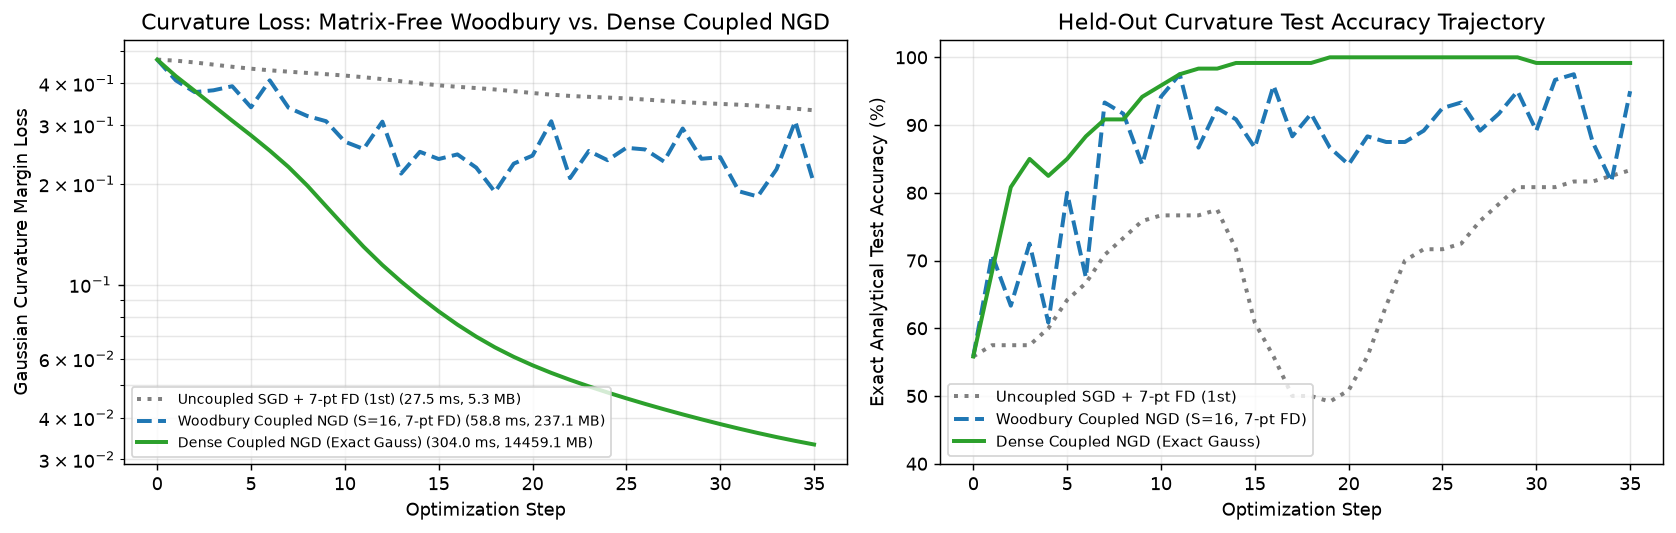

In [6]:
def compare_dense_vs_woodbury_coupled_ngd(n_steps: int = 35):
    results_ngd = {}
    rng_sub = torch.Generator().manual_seed(19)

    for mode, label, col, ls in [
        ("sgd_fd", "Uncoupled SGD + 7-pt FD (1st)", "#7f7f7f", ":"),
        ("woodbury_fd", "Woodbury Coupled NGD (S=16, 7-pt FD)", "#1f77b4", "--"),
        ("dense_exact", "Dense Coupled NGD (Exact Gauss)", "#2ca02c", "-"),
    ]:
        mdl = MoonsMLP(
            layer_dims=LAYER_DIMS,
            activation=HIDDEN_ACTIVATION,
            output_activation=OUTPUT_ACTIVATION,
            seed=7,
        )
        losses, accs = [], []

        with profile(activities=[ProfilerActivity.CPU], profile_memory=True) as prof:
            mdl.zero_grad()
            if mode == "dense_exact":
                g_m, K_m = compute_fast_graph_geometry(mdl, X_train, params=dict(mdl.named_parameters()))
            else:
                g_m, K_m = compute_fd_graph_curvature(mdl, X_train)
            l_m, _ = curvature_margin_loss(K_m, y_train, g_m, margin=0.40, lambda_vol=0.02, lambda_iso=0.005, k_clip=10.0, n_classes=N_CLASSES)
            l_m.backward()
            if mode == "dense_exact":
                _ = compute_coupled_geometric_metric(mdl, X_train, y_train, task="curvature", margin=0.40, damping=0.025)
            elif mode == "woodbury_fd":
                gf = torch.cat([p.grad.reshape(-1) if p.grad is not None else torch.zeros(p.numel(), dtype=X_train.dtype) for p in mdl.parameters()])
                _ = woodbury_coupled_ngd_direction(mdl, X_train[:16], y_train[:16], gf, task="curvature", margin=0.40)
        mem_mb = sum(e.cpu_memory_usage for e in prof.key_averages() if e.cpu_memory_usage > 0) / (1024.0 * 1024.0)

        mdl = MoonsMLP(
            layer_dims=LAYER_DIMS,
            activation=HIDDEN_ACTIVATION,
            output_activation=OUTPUT_ACTIVATION,
            seed=7,
        )
        sgd_opt = torch.optim.SGD(mdl.parameters(), lr=0.045, momentum=0.9) if mode == "sgd_fd" else None
        t0 = time.perf_counter()

        for _ in range(n_steps):
            mdl.zero_grad()
            if mode == "dense_exact":
                g_tr, K_tr = compute_fast_graph_geometry(mdl, X_train, params=dict(mdl.named_parameters()))
            else:
                g_tr, K_tr = compute_fd_graph_curvature(mdl, X_train)
            loss, _ = curvature_margin_loss(K_tr, y_train, g_tr, margin=0.40, lambda_vol=0.02, lambda_iso=0.005, k_clip=10.0, n_classes=N_CLASSES)
            losses.append(loss.item())
            accs.append(exact_test_accuracy(mdl, "curvature"))
            loss.backward()

            if mode == "sgd_fd":
                torch.nn.utils.clip_grad_norm_(mdl.parameters(), 5.0)
                sgd_opt.step()
            elif mode == "woodbury_fd":
                gf = torch.cat([p.grad.reshape(-1) if p.grad is not None else torch.zeros(p.numel(), dtype=X_train.dtype) for p in mdl.parameters()])
                idx_s = torch.randperm(X_train.shape[0], generator=rng_sub)[:16]
                nat_d, r_norm = woodbury_coupled_ngd_direction(mdl, X_train[idx_s], y_train[idx_s], gf, task="curvature", margin=0.40, damping=0.03)
                sc = min(1.0, 0.85 / r_norm)
                with torch.no_grad():
                    off = 0
                    for p in mdl.parameters():
                        n = p.numel()
                        p -= (0.26 * sc) * nat_d[off : off + n].reshape(p.shape)
                        off += n
            else:
                gf = torch.cat([p.grad.reshape(-1) if p.grad is not None else torch.zeros(p.numel(), dtype=X_train.dtype) for p in mdl.parameters()])
                G_d = compute_coupled_geometric_metric(mdl, X_train, y_train, task="curvature", margin=0.40, damping=0.025)
                nat_d = torch.linalg.solve(G_d, gf)
                r_norm = torch.sqrt(torch.clamp(nat_d @ (G_d @ nat_d), min=1e-12)).item()
                sc = min(1.0, 0.85 / r_norm)
                with torch.no_grad():
                    off = 0
                    for p in mdl.parameters():
                        n = p.numel()
                        p -= (0.28 * sc) * nat_d[off : off + n].reshape(p.shape)
                        off += n

        ms_per_step = (time.perf_counter() - t0) * 1000.0 / n_steps
        accs.append(exact_test_accuracy(mdl, "curvature"))
        with torch.no_grad():
            g_f, K_f = compute_fast_graph_geometry(mdl, X_train)
            losses.append(curvature_margin_loss(K_f, y_train, g_f, margin=0.40, lambda_vol=0.02, lambda_iso=0.005, k_clip=10.0, n_classes=N_CLASSES)[0].item())

        results_ngd[label] = {"loss": losses, "acc": accs, "ms": ms_per_step, "mb": mem_mb, "col": col, "ls": ls}
        print(f"{label:<40} | {ms_per_step:7.2f} ms/step | {mem_mb:7.2f} MB/step | Final Loss: {losses[-1]:.4f} | Exact Test Acc: {accs[-1]:6.2f}%")

    return results_ngd

ngd_comp = compare_dense_vs_woodbury_coupled_ngd(n_steps=35)

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.2))
for label, d in ngd_comp.items():
    axes[0].plot(d["loss"], color=d["col"], ls=d["ls"], lw=2.2, label=f"{label} ({d['ms']:.1f} ms, {d['mb']:.1f} MB)")
    axes[1].plot(d["acc"], color=d["col"], ls=d["ls"], lw=2.2, label=label)

axes[0].set_yscale("log")
axes[0].set_xlabel("Optimization Step")
axes[0].set_ylabel("Gaussian Curvature Margin Loss")
axes[0].set_title("Curvature Loss: Matrix-Free Woodbury vs. Dense Coupled NGD")
axes[0].legend(fontsize=8.0)
axes[0].grid(alpha=0.3, which="both")

axes[1].set_xlabel("Optimization Step")
axes[1].set_ylabel("Exact Analytical Test Accuracy (%)")
axes[1].set_title("Held-Out Curvature Test Accuracy Trajectory")
axes[1].set_ylim(min(45.0, 100.0 / N_CLASSES - 10.0), 102.5)
axes[1].legend(fontsize=8.3)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()